In [1]:
import pandas as pd
import rpy2
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import cellseg_benchmark._constants as _constants
from cellseg_benchmark.metrics import clean_method_name

/home/ubuntu/miniforge3/envs/analysis/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/ubuntu/miniforge3/envs/analysis/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%load_ext rpy2.ipython

2026-11-03 13:09:48,499 [INFO]: cffi mode is CFFI_MODE.ANY
2026-11-03 13:09:48,501 [INFO]: R home found: /home/ubuntu/miniforge3/envs/analysis/lib/R
2026-11-03 13:09:49,116 [INFO]: R library path: 
2026-11-03 13:09:49,117 [INFO]: LD_LIBRARY_PATH: 
2026-11-03 13:09:49,153 [INFO]: Default options to initialize R: rpy2, --quiet, --no-save
2026-11-03 13:09:49,787 [INFO]: Environment variable "PWD" redefined by R and overriding existing variable. Current: "/", R: "/dss/dsshome1/00/ra87rib"
2026-11-03 13:09:50,469 [INFO]: R is already initialized. No need to initialize.


In [3]:
!mamba install -y -q -p {sys.prefix} -c conda-forge r-svglite r-dplyr r-tibble r-ggplot2 r-rcolorbrewer r-ggforce r-jsonlite

Preparing transaction: ...working... done
Verifying transaction: ...working... done
Executing transaction: ...working... done


In [4]:
%%R
if (!requireNamespace("funkyheatmap", quietly = TRUE))
  install.packages("funkyheatmap", repos = "https://cloud.r-project.org")

* installing *source* package ‘funkyheatmap’ ...
** this is package ‘funkyheatmap’ version ‘0.5.2’
** package ‘funkyheatmap’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** data
*** moving datasets to lazyload DB
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
*** copying figures
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (funkyheatmap)


trying URL 'https://cloud.r-project.org/src/contrib/funkyheatmap_0.5.2.tar.gz'
Content type 'application/x-gzip' length 1745259 bytes (1.7 MB)
downloaded 1.7 MB


The downloaded source packages are in
	‘/tmp/Rtmpc18OoQ/downloaded_packages’
Updating HTML index of packages in '.Library'
Making 'packages.html' ... done


In [5]:
main_dir = Path("/dss/dsshome1/00/ra87rib/cellseg-benchmark")

In [53]:
cohorts = ["aging"]
exclude = ["Negative_Control_Visium", "Watershed_Merlin"]  # methods left out of the tables
output_folders = ["general_stats", "assigned_transcripts", "cell_type_metrics", "marker_gene_metrics", "ficture", "cell_density", "z_integrity"]

dfs_by = {c: {csv.stem: pd.read_csv(csv, index_col=0)
              for name in output_folders
              for csv in (main_dir / "metrics" / c / name).glob("*.csv")# if "vascular" not in csv.name
             }
          for c in cohorts}
{c: len(d) for c, d in dfs_by.items()}

{'aging': 15}

In [54]:
dfs_by['aging'].keys()

dict_keys(['general_stats', 'assigned_transcript_counts', 'clustering_score_adata_vascular_subset_cell_type_revised', 'cell_type_distribution_adata_vascular_subset_cell_type_incl_zonation', 'clustering_score_adata_vascular_subset_cell_type_incl_zonation', 'clustering_score_adata_integrated_cell_type_revised', 'cell_type_distribution_adata_integrated_cell_type_revised', 'negative_marker_purity_all', 'MECR_score_vascular_celltypes', 'MECR_score_all', 'marker_f1_score_cell_type_revised', 'marker_f1_score_cell_type_revised_vascular_celltypes', 'marker_f1_score_cell_type_revised_all', 'ficture_f1', 'cell_density'])

In [55]:
def norm_fixed(s, lo, hi, invert=False):
    n = ((s - lo) / (hi - lo)).clip(0, 1)
    return 1 - n if invert else n

def norm01(s):
    lo, hi = s.min(), s.max()
    return (s - lo) / (hi - lo) if hi > lo else s * 0 + 0.5

def per_method(df, cols, key="method"):
    return df.query("sample != 'all'").groupby(key)[cols].mean()

def build_benchmark_table_vasc_subset(dfs, exclude=()):
    gs = dfs["general_stats"].query("cell_type_revised == 'vascular_subset'")
    at = dfs["assigned_transcript_counts"].groupby(["sample", "method"])[["assigned_count_qced", "total_count"]].sum()
    at["pct_assigned_qced"] = at.assigned_count_qced / at.total_count
    at["tpc"] = at.assigned_count_qced / gs.set_index(["sample", "method"]).n_cells
    at = at.reset_index()

    mecr = per_method(dfs["MECR_score_vascular_celltypes"].query("gene1 == 'all'"), "MECR") #changed
    tpc = per_method(at, "tpc").reindex(mecr.index) #or pct_tx
    real = ~mecr.index.str.startswith("Negative_Control") & tpc.notna()
    fit = np.polyfit(np.log10(tpc[real]), mecr[real], 1)
    mf1 = (per_method(dfs["marker_f1_score_cell_type_revised_vascular_celltypes"], "f1_score", ["sample", "method", "cell_type"]) #changed
           .groupby(["sample", "method"]).mean().groupby("method").mean())
    z = dfs["z_integrity_vascular_celltypes"].query("sample != 'all_samples' and signal_threshold == 2 and vsi_threshold == 0.7").groupby("method").low_vsi_pct.mean()
    ff1 = (dfs["ficture_f1"]
           .query("cell_type in ['ECs', 'SMCs', 'Pericytes', 'VLMCs', 'BAMs'] and sample != 'all_samples'")
           .groupby("method").f1.mean())

    raw = pd.concat([
        per_method(gs, ["volume_final", "elongation", "intensities_PolyT", "intensities_DAPI", "n_cells"]),
        per_method(dfs["clustering_score_adata_vascular_subset_cell_type_incl_zonation"], ["silhouette_score"]),
        mecr, (mecr - np.polyval(fit, np.log10(tpc))).rename("MECR_adj"),
        mf1.rename("marker_f1"), ff1.rename("ficture_f1_score"), z.rename("low_vsi_pct"),
    ], axis=1).drop(index=list(exclude), errors="ignore")

    bounds = {
        "silhouette_score":            (-1.0, 1.0, False),
        #"MECR":                        (0.0, 1.0, False),
        "MECR_adj":                    (-0.02, 0.02, True),
        "low_vsi_pct":                 (0.0, 100.0, True),
        "marker_f1":                   (0.0, 1.0, False),
        "ficture_f1_score":            (0.0, 1.0, False),
    }
    descriptive = ["volume_final", "elongation", "intensities_PolyT", "intensities_DAPI"]

    df = raw.copy()
    df["total_score"] = pd.DataFrame({c: norm_fixed(df[c], *b) for c, b in bounds.items()}).mean(axis=1)
    df["total_score_label"] = df.total_score.map(lambda x: f" {x:.2f}")
    for c, b in bounds.items():
        df[c] = norm01(norm_fixed(df[c], *b))
    for c in descriptive:
        df[c] = norm01(df[c])
    df = df.sort_values("total_score", ascending=False).rename_axis("id").reset_index()
    df["id"] = df.id.map(clean_method_name)
    return df, raw

In [56]:
%%R
plot_benchmark_heatmap_vasc_subset <- function(df_funky, out_dir, metric_labels) {
  library(funkyheatmap)
  library(dplyr)
  library(tibble)
  library(ggplot2)
  library(RColorBrewer)

  df_funky$sep1 <- ""

  col_spec <- tribble(
    ~id,                          ~group,        ~geom,       ~palette,       ~name,           ~opts,
    "id",                         "",            "text",      NA,             "",              list(width = 8, hjust = 0),
    "total_score",                "overall",     "bar",       "agg",          "Total",         list(width = 2),
    "total_score_label",          "overall",     "text",      NA,             "",              list(overlay = TRUE, size = 2.5, hjust = 0),
    "silhouette_score",           "clustering",  "funkyrect", "purples",      "Silhouette",    list(),
      
    "MECR_adj",                   "marker",      "funkyrect", "reds",         "MECR",          list(),
    "marker_f1",                  "marker",      "funkyrect", "reds",         "Marker F1",     list(),
    "ficture_f1_score",           "ficture",     "funkyrect", "oranges",      "Ficture F1",    list(),
    "low_vsi_pct",                "doublets",    "funkyrect", "greys",        "Z integrity",   list(),
      
    "sep1",                       "",            "text",      NA,             "",              list(width = 0.75),
      
    "volume_final",               "seg",         "funkyrect", "greens",       "Volume",        list(),
    "elongation",                 "seg",         "funkyrect", "greens",       "Elongation",    list(),
    "intensities_PolyT",          "seg",         "funkyrect", "greens",       "PolyT",         list(),
    "intensities_DAPI",           "seg",         "funkyrect", "greens",       "DAPI",          list(),
  )

  column_info <- col_spec %>%
    left_join(metric_labels, by = "id", suffix = c("", "_label")) %>%
    mutate(name = coalesce(name_label, name), options = opts, legend = FALSE) %>%
    select(-name_label, -opts)

  column_groups <- tribble(
    ~group,        ~level1,       ~palette,
    "overall",     "Overall",     "agg",
    "clustering",  "Clustering",  "purples",
    "marker",      "Marker",      "reds",
    "ficture",     "Ficture",     "oranges",
    "doublets",    "Z",           "greys",
    "seg",         "General",     "greens"
  )

  palettes <- list(
    agg         = brewer.pal(9, "YlOrBr"),
    greens      = brewer.pal(9, "Greens"),
    greens_dark = brewer.pal(9, "Greens")[3:7],
    blues       = brewer.pal(9, "Blues"),
    purples     = brewer.pal(9, "Purples"),
    reds        = brewer.pal(9, "Reds"),
    oranges     = brewer.pal(9, "Oranges"),
    greys       = brewer.pal(9, "Greys")
  )

  legends <- list(
    list(title = "Score",   palette = "agg",    geom = "bar",       
      labels = c("0", "", "0.5", "", "1"), size = c(0, 0.25, 0.5, 0.75, 1),     
      color = brewer.pal(9, "YlOrBr")[c(1, 3, 5, 7, 9)]
    ),
    list(title = "Metrics", palette = "greens", geom = "funkyrect", 
      labels = c("0", "", "0.5", "", "1"), size = c(0.1, 0.3, 0.5, 0.75, 1.0), 
      color = brewer.pal(9, "Greys")[c(1, 3, 5, 7, 9)],
      label_hjust = 0
    ),
    list(palette = "purples",     enabled = FALSE),
    list(palette = "reds",        enabled = FALSE),
    list(palette = "oranges",     enabled = FALSE),
    list(palette = "greys",       enabled = FALSE),
    list(palette = "blues",       enabled = FALSE),
    list(palette = "greens_dark", enabled = FALSE)
  )

  g <- funky_heatmap(
    df_funky,
    column_info   = column_info,
    column_groups = column_groups,
    palettes      = palettes,
    legends       = legends,
    scale_column  = FALSE,
    position_args = position_arguments(
      expand_xmax = 3, expand_ymin = 0.5,
      expand_ymax = 4, col_annot_offset = 3, col_annot_angle = 45
    )
  )

  for (ext in c("pdf", "svg"))
    ggsave(file.path(out_dir, paste0("benchmark_table.", ext)), g, width = g$width, height = g$height,
           device = if (ext == "pdf") cairo_pdf else "svg")
  g
}

In [57]:
metric_labels = pd.DataFrame(list(_constants.metric_names.items()), columns=["id", "name"])

In [60]:
tmp = dfs_by['aging']["clustering_score_adata_vascular_subset_cell_type_incl_zonation"]
tmp[tmp['method']=="Ficture_segments_dapi"]

,method,sample,calinski_harabasz_score,silhouette_score
676,Ficture_segments_dapi,aging_s11_r1,3.293312,-0.053305
677,Ficture_segments_dapi,aging_s7_r1,3.114829,-0.040353
678,Ficture_segments_dapi,aging_s7_r2,4.085697,0.026619
679,Ficture_segments_dapi,aging_s6_r0,3.694083,-0.006011
680,Ficture_segments_dapi,aging_s10_r1,4.034135,-0.020276
681,Ficture_segments_dapi,aging_s10_r2,3.115565,-0.030468
682,Ficture_segments_dapi,aging_s11_r0,2.523465,-0.036507
683,Ficture_segments_dapi,aging_s8_r2,3.812049,-0.025851
684,Ficture_segments_dapi,aging_s5_r1,3.775594,-0.026035
685,Ficture_segments_dapi,aging_s1_r1,4.739507,0.027124


ℹ No row info was provided, assuming all rows in `data` are to be plotted.
ℹ Row info did not contain group information, assuming rows are ungrouped.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


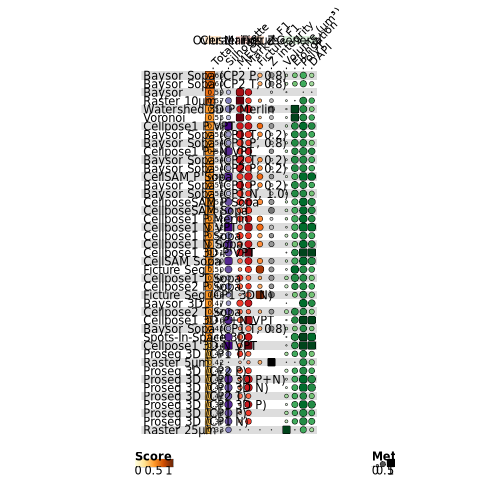

In [59]:
for name, dfs in dfs_by.items():
    for key, value in dfs.items():
        dfs[key] = value[value['method']!="Negative_Control_Visium"]
    df_funky, raw = build_benchmark_table_vasc_subset(dfs)
    df_funky_sub = df_funky[df_funky['id']!="Visium"]
    out_dir = str(main_dir / "metrics" / name / "benchmark_table_vasc")
    %R -i df_funky_sub -i out_dir -i metric_labels print(plot_benchmark_heatmap_vasc_subset(df_funky_sub, out_dir, metric_labels))